# 🤖 O robô entregador: o ciclo agente–ambiente

O hospital comprou o **RL-1**, um robô que leva remédios pelos corredores até a **farmácia** ✚. Ninguém programou o caminho: ele precisa descobrir sozinho, por **tentativa e erro** — como o cachorro que aprende pelo petisco (slide 16).

Neste notebook você vai:
1. Conhecer o ambiente e os **cinco conceitos-chave** (slide 26) em código.
2. **Ser a política** do robô: você escolhe cada ação e vê o ciclo *estado → ação → recompensa → novo estado* acontecer (slide 29).
3. Ver o robô com **política aleatória** — o ponto de partida do slide 37.
4. **Escrever a sua política** e colocá-la para competir (slide 34).
⏱️ Tempo estimado em aula: 15–20 minutos.

| Conceito (slide 26) | No hospital |
|---|---|
| **Agente** | o robô RL-1 |
| **Ambiente** | o andar do hospital: corredores, paredes e a farmácia |
| **Estado** $S_t$ | a posição do robô `(linha, coluna)` — totalmente observável |
| **Ação** $A_t$ | `cima`, `baixo`, `esquerda`, `direita` |
| **Recompensa** $R_{t+1}$ | **−1 por passo** (slide 37): bateria gasta. O episódio termina na farmácia |

> Como a recompensa é −1 por passo, **maximizar a recompensa acumulada = chegar no menor número de passos.**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch, Circle, FancyArrow
from matplotlib import animation
from IPython.display import HTML, display, clear_output
from collections import deque
import ipywidgets as widgets

np.random.seed(0)
ACOES = ['cima', 'baixo', 'esquerda', 'direita']
SETAS = {'cima': '↑', 'baixo': '↓', 'esquerda': '←', 'direita': '→'}

## 1. O ambiente

O mapa é um texto: `S` = garagem do robô (início), `#` = parede, `.` = corredor, `F` = farmácia (fim).

O ambiente "conversa" com o agente por **dois comandos** — o mesmo padrão dos ambientes de RL em Python (slide 39):

- `reset()` → começa um episódio e devolve o estado inicial;
- `step(acao)` → executa a ação e devolve `(novo_estado, recompensa, fim)`.

In [2]:
MAPA = [
    "S..#..",
    ".#.#.#",
    ".#....",
    "...##.",
    "##..#.",
    "...#.F",
]


class Hospital:
    MOV = {'cima': (-1, 0), 'baixo': (1, 0), 'esquerda': (0, -1), 'direita': (0, 1)}

    def __init__(self, mapa):
        self.mapa = [list(linha) for linha in mapa]
        self.n_linhas, self.n_colunas = len(mapa), len(mapa[0])
        achar = lambda ch: next((l, c) for l in range(self.n_linhas) for c in range(self.n_colunas)
                                if self.mapa[l][c] == ch)
        self.inicio, self.farmacia = achar('S'), achar('F')
        self.reset()

    def livre(self, l, c):
        return 0 <= l < self.n_linhas and 0 <= c < self.n_colunas and self.mapa[l][c] != '#'

    def reset(self, inicio=None):
        """Começa um episódio. Devolve o estado inicial."""
        self.estado = inicio or self.inicio
        return self.estado

    def step(self, acao):
        """Executa a ação. Devolve (novo_estado, recompensa, fim)."""
        dl, dc = self.MOV[acao]
        l, c = self.estado[0] + dl, self.estado[1] + dc
        if self.livre(l, c):          # corredor livre: anda
            self.estado = (l, c)
        # parede ou borda: o robô fica onde está (mas gastou o passo)
        recompensa = -1               # slide 37: −1 por passo
        fim = self.estado == self.farmacia
        return self.estado, recompensa, fim


hospital = Hospital(MAPA)
estados = [(l, c) for l in range(hospital.n_linhas) for c in range(hospital.n_colunas) if hospital.livre(l, c)]
print(f"Estado inicial: {hospital.reset()}  |  farmácia: {hospital.farmacia}  |  {len(estados)} estados possíveis")
print("Um passo para a direita:", hospital.step('direita'))

Estado inicial: (0, 0)  |  farmácia: (5, 5)  |  25 estados possíveis
Um passo para a direita: ((0, 1), -1, False)


### O ciclo agente–ambiente em código (slide 29)

Um episódio inteiro cabe em poucas linhas: o ambiente começa (`reset`), e a cada passo a **política** escolhe a ação, o ambiente responde (`step`) e o laço recomeça — até o episódio terminar. Esta função é usada no resto do notebook (e você vai escrever uma parecida no exercício do armazém).

In [3]:
def rodar_episodio(politica, amb=None, max_passos=300, inicio=None):
    """Um episódio completo com a política dada. Devolve a lista [(estado, ação, recompensa), ...]."""
    amb = amb or hospital
    s = amb.reset(inicio)
    traj = []
    for _ in range(max_passos):
        a = politica(s)
        s2, r, fim = amb.step(a)
        traj.append((s, a, r))
        s = s2
        if fim:
            break
    traj.append((s, None, 0))   # estado final
    return traj

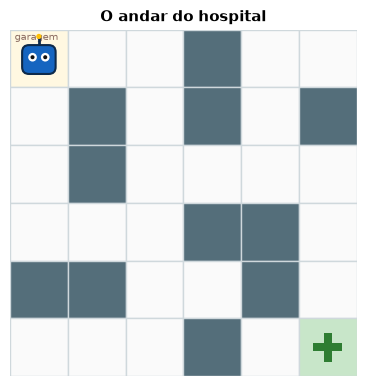

In [4]:
# @title Desenho, animação e episódio (rode e siga em frente)
def desenhar_robo(ax, x, y, cor='#1565C0'):
    ax.add_patch(FancyBboxPatch((x - .27, y - .25), .54, .46, boxstyle='round,pad=0.02,rounding_size=0.12',
                                fc=cor, ec='#0D2A4A', lw=1.5, zorder=10))
    for dx in (-.11, .11):
        ax.add_patch(Circle((x + dx, y + .02), .075, fc='white', zorder=11))
        ax.add_patch(Circle((x + dx, y + .02), .035, fc='#111', zorder=12))
    ax.plot([x, x], [y + .23, y + .36], color='#0D2A4A', lw=2, zorder=9)
    ax.add_patch(Circle((x, y + .38), .045, fc='#FFC107', zorder=11))


def desenhar_hospital(ax, amb, robo=None, rastro=None, valores=None, politica=None, titulo=None):
    """Desenha o mapa. Opcional: robô, rastro, números por casa (valores) e setas (política)."""
    nl = amb.n_linhas
    xy = lambda l, c: (c + .5, nl - 1 - l + .5)
    for l in range(nl):
        for c in range(amb.n_colunas):
            ch = amb.mapa[l][c]
            cor = {'#': '#546E7A', 'F': '#C8E6C9', 'S': '#FFF8E1'}.get(ch, '#FAFAFA')
            ax.add_patch(Rectangle((c, nl - 1 - l), 1, 1, fc=cor, ec='#CFD8DC', lw=1))
            x, y = xy(l, c)
            if ch == 'F':   # cruz da farmácia
                ax.add_patch(Rectangle((x - .07, y - .25), .14, .5, fc='#2E7D32', zorder=3))
                ax.add_patch(Rectangle((x - .25, y - .07), .5, .14, fc='#2E7D32', zorder=3))
            if ch == 'S':
                ax.text(c + .08, nl - 1 - l + .82, 'garagem', fontsize=7, color='#8D6E63')
            if valores is not None and (l, c) in valores and ch != '#':
                ax.text(x, y - .4, f'{valores[(l, c)]:.0f}', ha='center', fontsize=9, color='#37474F', zorder=6)
            if politica is not None and ch not in '#F':
                dl, dc = Hospital.MOV[politica((l, c))]
                ax.add_patch(FancyArrow(x - dc * .2, y + .08 + dl * .17, dc * .34, -dl * .3, width=.05,
                                        head_width=.2, head_length=.14, color='#E65100', zorder=7))
    if rastro:
        pts = [xy(*s) for s in rastro]
        ax.plot([p[0] for p in pts], [p[1] for p in pts], '-', color='#1565C0', alpha=.35, lw=5, zorder=8)
    if robo is not None:
        desenhar_robo(ax, *xy(*robo))
    ax.set_xlim(0, amb.n_colunas); ax.set_ylim(0, nl); ax.set_aspect('equal'); ax.axis('off')
    if titulo:
        ax.set_title(titulo, fontsize=11, fontweight='bold')


def animar(trajetorias, titulos, max_quadros=60):
    """Anima episódios lado a lado (episódios longos são acelerados)."""
    n = len(trajetorias)
    fig, axes = plt.subplots(1, n, figsize=(3.6 * n, 4.1), dpi=60)
    axes = np.atleast_1d(axes)
    pulo = [max(1, -(-len(t) // max_quadros)) for t in trajetorias]
    n_q = max(-(-len(t) // p) for t, p in zip(trajetorias, pulo)) + 5

    def quadro(k):
        for ax, traj, tit, p in zip(axes, trajetorias, titulos, pulo):
            ax.clear()
            i = min(k * p, len(traj) - 1)
            chegou = traj[i][0] == hospital.farmacia
            fim = '  ✔ chegou!' if chegou else ('' if i < len(traj) - 1 else '  ✘ desistiu')
            desenhar_hospital(ax, hospital, robo=traj[i][0], rastro=[s for s, _, _ in traj[:i + 1]],
                              titulo=f'{tit}\npasso {i} | retorno {-i}{fim}')
        return []

    anim = animation.FuncAnimation(fig, quadro, frames=n_q, interval=200)
    plt.close(fig)
    return HTML(anim.to_jshtml(default_mode='once'))


fig, ax = plt.subplots(figsize=(4.5, 4.5))
desenhar_hospital(ax, hospital, robo=hospital.inicio, titulo='O andar do hospital')
plt.show()

## 2. Você é a política

Use os botões para guiar o robô. A cada clique, a tabela registra **uma volta do ciclo** (slide 29):

$$S_t \;\xrightarrow{\text{você escolhe } A_t}\; \text{ambiente} \;\longrightarrow\; R_{t+1},\; S_{t+1}$$

e o **retorno** $G$ = soma das recompensas até agora.

> **Desafio:** chegue à farmácia com o **maior retorno possível**. Quanto é o melhor? Depois, bata de propósito numa parede: o que muda na tabela?

In [5]:
# @title Controle do robô (rode para jogar)
def jogar():
    amb = Hospital(MAPA)
    estado = {'s': amb.reset(), 't': 0, 'G': 0, 'log': [], 'rastro': [amb.inicio], 'fim': False}
    tela, tabela, aviso = widgets.Output(), widgets.HTML(), widgets.HTML()
    botoes = {a: widgets.Button(description=SETAS[a], layout=widgets.Layout(width='48px')) for a in ACOES}
    novo = widgets.Button(description='Recomeçar', button_style='warning')

    def redesenhar():
        with tela:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(3.8, 3.8))
            desenhar_hospital(ax, amb, robo=estado['s'], rastro=estado['rastro'])
            plt.show()
        linhas = ''.join(f'<tr><td>{t}</td><td>{s}</td><td>{a}</td><td>{r:+d}</td><td>{s2}</td><td><b>{G:+d}</b></td></tr>'
                         for t, s, a, r, s2, G in estado['log'][-8:])
        tabela.value = ('<table style="font-family:monospace;border-collapse:collapse" cellpadding="4">'
                        '<tr style="background:#ECEFF1"><th>t</th><th>Sₜ</th><th>Aₜ</th><th>Rₜ₊₁</th>'
                        f'<th>Sₜ₊₁</th><th>G</th></tr>{linhas}</table>')

    def agir(a):
        if estado['fim']:
            return
        s = estado['s']
        s2, r, fim = amb.step(a)
        estado['G'] += r
        estado['log'].append((estado['t'], s, a, r, s2, estado['G']))
        estado.update(s=s2, t=estado['t'] + 1, fim=fim)
        estado['rastro'].append(s2)
        if fim:
            aviso.value = (f'<b style="color:#2E7D32">✚ Remédio entregue em {estado["t"]} passos! '
                           f'Retorno G = {estado["G"]}.</b>')
        elif s2 == s:
            aviso.value = '<span style="color:#C62828">Bateu! Ficou no lugar, mas a recompensa foi −1 do mesmo jeito.</span>'
        else:
            aviso.value = ''
        redesenhar()

    def recomecar(_=None):
        estado.update(s=amb.reset(), t=0, G=0, log=[], rastro=[amb.inicio], fim=False)
        aviso.value = ''
        redesenhar()

    for a, b in botoes.items():
        b.on_click(lambda _, a=a: agir(a))
    novo.on_click(recomecar)
    controles = widgets.VBox([
        widgets.HBox([widgets.Label(' ', layout=widgets.Layout(width='52px')), botoes['cima']]),
        widgets.HBox([botoes['esquerda'], widgets.Label(' ', layout=widgets.Layout(width='52px')), botoes['direita']]),
        widgets.HBox([widgets.Label(' ', layout=widgets.Layout(width='52px')), botoes['baixo']]),
        novo])
    recomecar()
    display(widgets.HBox([tela, widgets.VBox([controles, aviso, tabela])]))

In [ ]:
jogar()

## 3. A política inicial: aleatória (slide 37)

Um robô recém-ligado não sabe nada: sorteia uma das quatro ações, todas com a mesma chance. Isso é uma **política estocástica** $\pi(a|s) = 1/4$.

> **Palpite (em duplas: um prevê, o outro roda):** o caminho mais curto tem **10 passos**. Quantos passos, em média, o robô aleatório leva? 20? 50? 100?

In [6]:
def politica_aleatoria(estado):
    return np.random.choice(ACOES)


np.random.seed(1)
episodio = rodar_episodio(politica_aleatoria)
print(f"Este episódio: {len(episodio) - 1} passos  →  retorno G = {-(len(episodio) - 1)}")
animar([episodio], ['Política aleatória'])

Este episódio: 273 passos  →  retorno G = -273


In [7]:
np.random.seed(0)
passos = np.array([len(rodar_episodio(politica_aleatoria, max_passos=2000)) - 1 for _ in range(1000)])
print(f"1000 episódios aleatórios: em média {passos.mean():.0f} passos (o melhor possível é 10).")

1000 episódios aleatórios: em média 490 passos (o melhor possível é 10).


## 4. Escreva a sua política (slide 34)

Uma **política** é só uma função: recebe o estado e devolve a ação, $a = \pi(s)$. Abaixo há um exemplo **fraco de propósito**. Rode, veja as setas, e depois **escreva uma melhor**.

> Você pode usar `if`s com `linha` e `coluna`, ou até um **dicionário estado → ação**, como `tabela = {(0, 0): 'direita', ...}` — guarde essa ideia: é exatamente o que a Q-table vai aprender sozinha mais adiante.

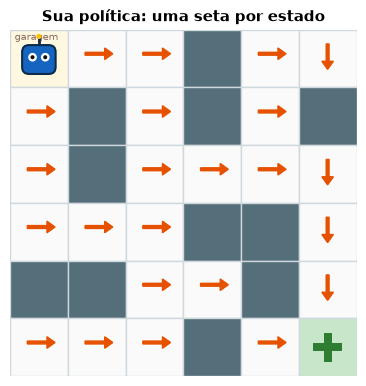

In [8]:
def minha_politica(estado):
    linha, coluna = estado
    # ✏️ Troque esta regra pela sua. Devolva 'cima', 'baixo', 'esquerda' ou 'direita'.
    if coluna < 5:
        return 'direita'
    return 'baixo'


fig, ax = plt.subplots(figsize=(4.5, 4.5))
desenhar_hospital(ax, hospital, robo=hospital.inicio, politica=minha_politica, titulo='Sua política: uma seta por estado')
plt.show()

### A competição

Cada política joga **200 episódios** (no máximo 200 passos cada). Também entram:
- a **política perfeita**, calculada a partir do mapa, como referência;
- a **sua política com 20% de acaso** — uma política estocástica, como o robô de recomendação do slide 34 (80% a escolha favorita, 20% explora).

> **Palpite:** a versão com 20% de acaso fica melhor ou pior que a sua política pura?

In [9]:
# Política perfeita: anda para a casa vizinha mais próxima da farmácia (distâncias por busca em largura)
dist = {hospital.farmacia: 0}
fila = deque([hospital.farmacia])
while fila:
    l, c = fila.popleft()
    for dl, dc in Hospital.MOV.values():
        viz = (l + dl, c + dc)
        if hospital.livre(*viz) and viz not in dist:
            dist[viz] = dist[(l, c)] + 1
            fila.append(viz)


def politica_perfeita(estado):
    l, c = estado
    return min(ACOES, key=lambda a: dist.get((l + Hospital.MOV[a][0], c + Hospital.MOV[a][1]), 999))


def com_acaso(politica, eps=0.2):
    """Versão estocástica: com probabilidade eps, sorteia uma ação qualquer."""
    return lambda s: np.random.choice(ACOES) if np.random.rand() < eps else politica(s)


def avaliar(politica, n=200, max_passos=200):
    passos = [len(rodar_episodio(politica, max_passos=max_passos)) - 1 for _ in range(n)]
    chegou = [p < max_passos for p in passos]
    return np.mean(chegou), -np.mean(passos)


np.random.seed(0)
competidores = {
    'aleatória': politica_aleatoria,
    'sua política': minha_politica,
    'sua + 20% de acaso': com_acaso(minha_politica),
    'perfeita (referência)': politica_perfeita,
}
print(f"{'política':24s} {'chegou':>8s} {'retorno médio':>14s}")
for nome, pol in competidores.items():
    taxa, G = avaliar(pol)
    print(f"{nome:24s} {taxa:8.0%} {G:14.1f}")

política                   chegou  retorno médio


aleatória                     26%         -177.3
sua política                   0%         -200.0
sua + 20% de acaso            91%          -79.0
perfeita (referência)        100%          -10.0


**O que observar**
- Uma política **determinística** ruim pode prender o robô para sempre: a mesma situação gera sempre a mesma ação errada. Rode a célula do desenho e veja onde as setas formam uma armadilha.
- Um pouco de **acaso** tira o robô do loop — é a primeira aparição da ideia de **exploração**, que vira o ε-greedy mais adiante.
- Agora é com você: **edite `minha_politica`** até chegar perto da perfeita. Qual foi o seu melhor retorno?

## Para pensar

1. **Recompensa atrasada (slide 29):** cada passo dá −1, igual para passos bons e ruins. Como o robô poderia saber *qual* passo foi bom?
2. **O agente cria os próprios dados (slide 17):** o robô aleatório passa muito tempo nos cantos sem saída. Que problema isso causa para aprender?
3. **Modelo (slide 36):** a política perfeita usou o mapa inteiro. Um robô que **não tem o mapa** teria que aprender como?

> No **exemplo 2** o ambiente fica traiçoeiro: gelo que escorrega e buracos. No fim dele, você vira o agente — sem enxergar o mapa.